# Block 1. Integrity and quality of the unified hotspot table

Owner: Vicente (M3). Plan: `docs/eda-plan.md`, block 1. Findings and filter decisions: `docs/findings/01-quality.md`.

Questions answered here:

1. Are there outages, partial months or duplicated rows? (1.1, 1.2)
2. Are the value ranges sane, and where do the sensors saturate? (1.3)
3. Is September 2026 (provisional NRT data) a real peak? (1.4)
4. Do the MODIS collection changes break the series? (1.5)
5. What is `fire_type`, and how do we flag static sources in NRT rows? (1.6)
6. What does dropping `low` confidence do? (1.7)
7. Geography: rows without region, border disagreements, areas outside the analysis. (1.8)
8. Scan geometry and re-observations. (1.9)
9. The filter we recommend, and its effect. (Decisions)

Day key: `burn_date` (06:00 to 06:00 local solar time, `docs/eda-plan.md`). If the table does not have the column yet
(M1 not merged), the notebook derives it with the same formula, so results do not change after the rebuild.
Everything in this notebook reads the table read-only. Derived files go to `NASA_Data_Sources/processed/quality/`.

In [1]:
from pathlib import Path
import json, shutil, os, datetime as dt, urllib.request
import duckdb, numpy as np, pandas as pd
import matplotlib.pyplot as plt
import shapely
from shapely.geometry import shape
from shapely.strtree import STRtree

pd.set_option('display.width', 200); pd.set_option('display.max_columns', 40); pd.set_option('display.max_rows', 120)
plt.rcParams.update({'figure.dpi': 100, 'axes.grid': True, 'grid.alpha': .25, 'axes.spines.top': False, 'axes.spines.right': False})

ROOT = next(p for p in [Path.cwd(), *Path.cwd().parents] if (p / 'CLAUDE.md').exists())
DATA = ROOT / 'NASA_Data_Sources'
HOT = (DATA / 'processed/hotspots').as_posix()
OUT = DATA / 'processed/quality'; OUT.mkdir(parents=True, exist_ok=True)

con = duckdb.connect()
con.execute("SET TimeZone='UTC'")
try: con.execute("SET enable_progress_bar=false")
except Exception: pass
SRC = f"read_parquet('{HOT}/*/*.parquet', hive_partitioning=true)"
cols = [r[0] for r in con.execute(f"DESCRIBE SELECT * FROM {SRC}").fetchall()]
HAS_BURN = 'burn_date' in cols
burn = "" if HAS_BURN else ", CAST((acq_datetime AT TIME ZONE 'UTC') + to_seconds(CAST(round(longitude/15*3600 - 6*3600) AS BIGINT)) AS DATE) AS burn_date"
con.execute(f"""CREATE VIEW h AS SELECT *, CAST(year AS INT) AS year_utc,
    CAST(acq_datetime AT TIME ZONE 'UTC' AS TIMESTAMP) AS ts {burn} FROM {SRC}""")
def q(sql): return con.sql(sql).df()

print('burn_date from table' if HAS_BURN else 'burn_date derived in this notebook')
q("select count(*) rows_, min(burn_date) first_day, max(burn_date) last_day from h")

burn_date derived in this notebook


,rows_,first_day,last_day
0,8042380,2000-10-31,2026-11-14


## 1.1 Availability per satellite and day

A day with zero detections over the whole domain can be a quiet day or an outage. We call a run of at least 3 zero days
a **likely outage** when the same satellite normally sees at least 5 detections per day in the 30 days around it.

In [2]:
avail = q('''
WITH rng AS (SELECT satellite, min(burn_date) a, max(burn_date) b FROM h GROUP BY 1),
days AS (SELECT satellite, unnest(generate_series(a, b, INTERVAL 1 DAY))::DATE d FROM rng),
have AS (SELECT satellite, burn_date d, count(*) n FROM h GROUP BY 1, 2)
SELECT days.satellite, days.d, coalesce(have.n, 0) n FROM days LEFT JOIN have USING (satellite, d)''')
avail['d'] = pd.to_datetime(avail.d)
piv = avail.pivot(index='d', columns='satellite', values='n')

rows = []
for sat in piv.columns:
    s = piv[sat].dropna()
    z = s[s == 0]
    if z.empty: continue
    grp = (z.index.to_series().diff().dt.days != 1).cumsum()
    for _, g in z.groupby(grp):
        a, b = g.index[0], g.index[-1]
        around = s[(s.index >= a - pd.Timedelta(days=30)) & (s.index <= b + pd.Timedelta(days=30))]
        expected = around[around > 0].median() if (around > 0).any() else np.nan
        others = piv.drop(columns=sat).loc[a:b].sum(axis=1).median()
        rows.append(dict(satellite=sat, start=a.date(), end=b.date(), days=len(g), normal_daily_count=expected, other_satellites_median=others))
gaps = pd.DataFrame(rows)
gaps['likely_outage'] = (gaps.days >= 3) & (gaps.normal_daily_count >= 5)
print('Zero-detection days per satellite (between its first and last day):')
display(avail.assign(zero=avail.n == 0).groupby('satellite').agg(days=('n', 'size'), zero_days=('zero', 'sum')).assign(pct=lambda x: (100 * x.zero_days / x.days).round(2)))
print('Runs of zero days (>= 3 days):')
display(gaps[gaps.days >= 3].sort_values('days', ascending=False).reset_index(drop=True))

Zero-detection days per satellite (between its first and last day):


,days,zero_days,pct
satellite,,,
Aqua,8899,61,0.69
NOAA-20,3150,6,0.19
NOAA-21,1355,4,0.30
Suomi-NPP,5401,53,0.98
Terra,9511,156,1.64


Runs of zero days (>= 3 days):


,satellite,start,end,days,normal_daily_count,other_satellites_median,likely_outage
0,Terra,2001-06-15,2001-07-02,18,16.5,0.0,True
1,Aqua,2022-03-31,2022-04-16,17,35.0,437.0,True
2,Suomi-NPP,2022-07-26,2022-08-09,15,714.5,722.0,True
3,Terra,2022-10-10,2022-10-22,13,114.0,879.0,True
4,Terra,2002-03-19,2002-03-27,9,36.0,0.0,True
5,Terra,2003-12-16,2003-12-23,8,57.5,76.0,True
6,Aqua,2002-07-30,2002-08-06,8,210.0,51.5,True
7,Terra,2016-02-19,2016-02-26,8,29.0,221.0,True
8,Suomi-NPP,2026-07-10,2026-07-15,6,167.0,557.5,True
9,Suomi-NPP,2024-07-10,2024-07-15,6,367.0,819.5,True


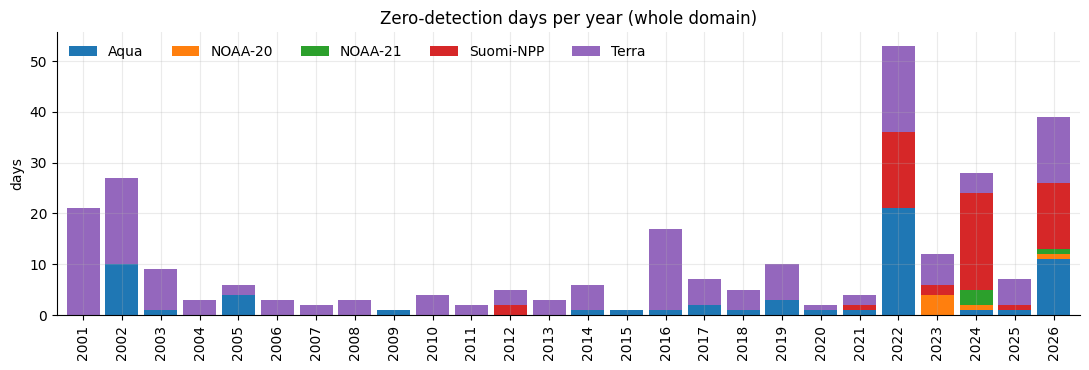

Start and end of each satellite (burn_date):


,satellite,first_day,last_day,rows_last_day,rows_first_day
0,Aqua,2002-07-04,2026-11-13,238,21
1,NOAA-20,2018-03-31,2026-11-13,1076,134
2,NOAA-21,2023-02-28,2026-11-13,1048,497
3,Suomi-NPP,2012-01-19,2026-11-01,105,271
4,Terra,2000-10-31,2026-11-14,7,24


In [3]:
z = avail[avail.n == 0].assign(year=lambda x: x.d.dt.year).groupby(['year', 'satellite']).size().unstack(fill_value=0)
ax = z.plot.bar(stacked=True, figsize=(11, 3.8), width=.85)
ax.set(title='Zero-detection days per year (whole domain)', xlabel='', ylabel='days'); ax.legend(ncol=5, frameon=False)
plt.tight_layout(); plt.show()

ends = q('''SELECT satellite, min(burn_date) first_day, max(burn_date) last_day,
  count(*) FILTER (WHERE burn_date = (SELECT max(burn_date) FROM h h2 WHERE h2.satellite = h.satellite)) rows_last_day,
  count(*) FILTER (WHERE burn_date = (SELECT min(burn_date) FROM h h2 WHERE h2.satellite = h.satellite)) rows_first_day FROM h GROUP BY 1 ORDER BY 1''')
print('Start and end of each satellite (burn_date):'); display(ends)

**Reading.** Zero days are rare (0.2% to 1.6% of days per satellite). Most single zero days are quiet winter days of a satellite with few detections (mainly Terra after its orbit drift).
The 19 runs of 3 or more days are all flagged `likely_outage`: in each one the satellite normally records at least 5 rows per day and, for the large ones (Aqua 17 days in 2022, Suomi-NPP 15 days in 2022,
Terra 18 days in 2001 and 13 days in 2022), the other satellites kept detecting, so they are not quiet days. We did not check them against NASA notices.
They are saved in `outage_days.csv` and must be excluded from any "days with fire" statistic. The last day of Terra (2026-11-14, 7 rows) is partial: the calendar stops at 2026-11-13.

## 1.2 Near duplicates, re-observations and file seams

Exact duplicates were already dropped by the build (3 rows). Here: rows from the same satellite, same minute and the same 0.001 degree cell (about 100 m),
re-observations of the same place by consecutive orbits, and the seams between the yearly files and the API files, and between the 5-day API chunks.

In [4]:
dup = q('''
WITH k AS (SELECT instrument, satellite, ts, round(latitude, 3) la, round(longitude, 3) lo, count(*) n FROM h GROUP BY ALL)
SELECT instrument, satellite, sum(n) rows_, sum(n - 1) FILTER (WHERE n > 1) extra_rows FROM k GROUP BY ALL ORDER BY 1, 2''')
dup['extra_pct'] = (100 * dup.extra_rows.fillna(0) / dup.rows_).round(3)
print('Same satellite, same minute, same 0.001 degree cell:'); display(dup)

reobs = q('''
WITH t AS (SELECT instrument, satellite, ts, lag(ts) OVER (PARTITION BY satellite, round(latitude, 3), round(longitude, 3) ORDER BY ts) prev FROM h)
SELECT instrument, satellite,
  count(*) FILTER (WHERE ts > prev AND ts - prev <= INTERVAL 3 HOUR) within_3h,
  count(*) FILTER (WHERE ts > prev AND ts - prev <= INTERVAL 24 HOUR) within_24h, count(*) n FROM t GROUP BY 1, 2 ORDER BY 1, 2''')
reobs['pct_within_3h'] = (100 * reobs.within_3h / reobs.n).round(2); reobs['pct_within_24h'] = (100 * reobs.within_24h / reobs.n).round(2)
print('Rows that repeat a point of the same satellite seen before (same 0.001 degree cell):'); display(reobs)

Same satellite, same minute, same 0.001 degree cell:


,instrument,satellite,rows_,extra_rows,extra_pct
0,MODIS,Aqua,1201272.0,NaN,0.000
1,MODIS,Terra,731177.0,NaN,0.000
2,VIIRS,NOAA-20,2066449.0,7283.0,0.352
3,VIIRS,NOAA-21,624426.0,2054.0,0.329
4,VIIRS,Suomi-NPP,3419056.0,13371.0,0.391


Rows that repeat a point of the same satellite seen before (same 0.001 degree cell):


,instrument,satellite,within_3h,within_24h,n,pct_within_3h,pct_within_24h
0,MODIS,Aqua,5,335,1201272,0.00,0.03
1,MODIS,Terra,1,397,731177,0.00,0.05
2,VIIRS,NOAA-20,4674,21566,2066449,0.23,1.04
3,VIIRS,NOAA-21,1414,7156,624426,0.23,1.15
4,VIIRS,Suomi-NPP,8370,40586,3419056,0.24,1.19


Rows per month and source around the end of the yearly files (31 Dec 2025):


instrument    MODIS                   VIIRS               
source     api_bbox country_yearly api_bbox country_yearly
m                                                         
2025-09           0           7397    21351          43357
2025-10           0           5823    18711          41902
2025-11           0           3917    12891          26617
2025-12           0           3040    10054          21529
2026-01        4574              0    55041              0
2026-02        2658              0    33494              0
2026-03        2668              0    30699              0

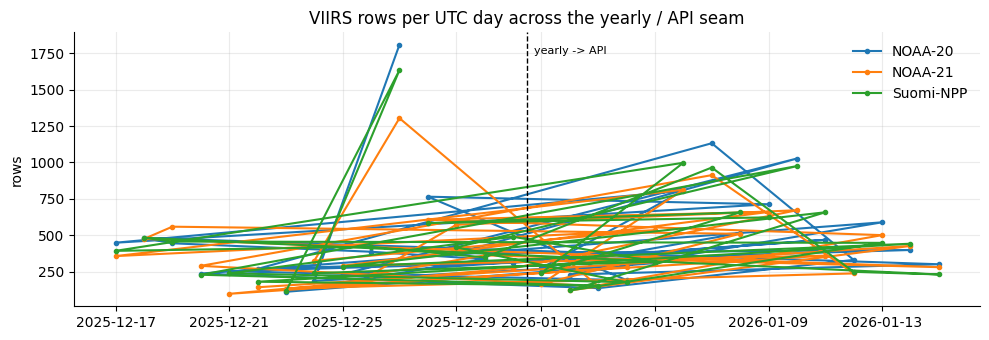

In [5]:
seam = q('''SELECT strftime(acq_date, '%Y-%m') m, instrument, source, count(*) n FROM h
  WHERE acq_date BETWEEN '2025-09-01' AND '2026-03-31' GROUP BY ALL ORDER BY 1, 2, 3''')
print('Rows per month and source around the end of the yearly files (31 Dec 2025):')
display(seam.pivot_table(index='m', columns=['instrument', 'source'], values='n', fill_value=0).astype(int))

d = q('''SELECT acq_date, satellite, count(*) n FROM h WHERE acq_date BETWEEN '2025-12-17' AND '2026-01-15' AND instrument = 'VIIRS' GROUP BY 1, 2''')
fig, ax = plt.subplots(figsize=(10, 3.5))
for sat, g in d.groupby('satellite'): ax.plot(pd.to_datetime(g.acq_date), g.n, marker='.', label=sat)
ax.axvline(pd.Timestamp('2025-12-31 12:00'), color='k', ls='--', lw=1); ax.text(pd.Timestamp('2025-12-31 18:00'), ax.get_ylim()[1] * .92, 'yearly -> API', fontsize=8)
ax.set(title='VIIRS rows per UTC day across the yearly / API seam', ylabel='rows'); ax.legend(frameon=False); plt.tight_layout(); plt.show()

In [6]:
# 5-day API chunks start on the 1st of each month: position of the UTC day inside its chunk.
# Mean rows per UTC day at each position, divided by the overall mean. Yearly files have no chunks: they are the control.
dd = q('''SELECT acq_date, source, instrument, count(*) n FROM h WHERE acq_date >= '2023-03-01' AND acq_date < '2026-11-01' GROUP BY ALL''')
dd['pos'] = ((pd.to_datetime(dd.acq_date).dt.day - 1) % 5) + 1
tab = dd.groupby(['source', 'instrument', 'pos']).n.mean().unstack('pos')
display((tab.div(tab.mean(axis=1), axis=0)).round(3))
print('A duplicated or missing day at a chunk seam would push position 1 or 5 away from 1.0 in the API rows, and not in the control.')

pos                            1      2      3      4      5
source         instrument                                   
api_bbox       MODIS       1.010  1.146  0.870  1.008  0.966
               VIIRS       1.047  1.028  0.996  0.939  0.989
country_yearly MODIS       0.980  1.085  0.869  1.105  0.961
               VIIRS       1.023  1.016  0.968  1.004  0.989

A duplicated or missing day at a chunk seam would push position 1 or 5 away from 1.0 in the API rows, and not in the control.


**Reading.** Near duplicates exist only in VIIRS (about 0.4% of rows: overlap of adjacent scan aggregation zones) and are not dropped.
Only 0.23% of VIIRS rows repeat a point of the same satellite seen within 3 hours, and 1% within 24 hours (consecutive orbits at high latitude): real re-observation, not an error. MODIS has almost none.
The yearly / API seam is smooth in rows per month and per day. In the 5-day chunk check, positions 1 and 5 stay within 5% of 1.0 in the API rows, the same noise as in the yearly-file control (which deviates up to 13% in MODIS because MODIS has few rows per day): no sign of lost or doubled days at the chunk seams.

## 1.3 Value ranges

FRP is in MW. Brightness temperature columns are MODIS T21 / T31 and VIIRS I4 / I5. A saturated channel clips the brightness (and can leave FRP at zero).

instrument,MODIS,VIIRS
n,1.932449e+06,6.109931e+06
frp_null,0.000000e+00,0.000000e+00
frp_negative,0.000000e+00,1.800000e+01
frp_zero,3.170000e+02,3.369000e+03
frp_p50,2.020000e+01,5.500000e+00
frp_p99,6.016000e+02,1.369000e+02
frp_p9999,4.391000e+03,6.270000e+02
frp_max,1.329500e+04,2.631000e+03
mir_min,3.000000e+02,0.000000e+00
mir_max,5.096000e+02,3.670000e+02


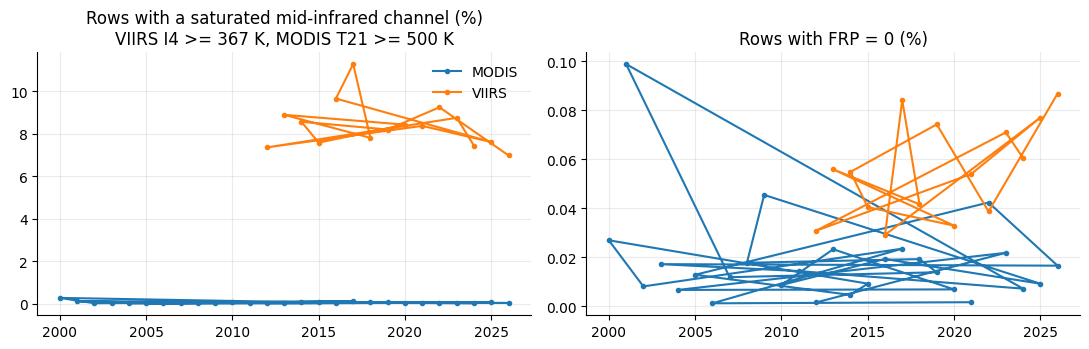

In [7]:
rng = q('''SELECT instrument,
  count(*) n,
  count(*) FILTER (WHERE frp_mw IS NULL) frp_null,
  count(*) FILTER (WHERE frp_mw < 0) frp_negative,
  count(*) FILTER (WHERE frp_mw = 0) frp_zero,
  round(quantile_cont(frp_mw, 0.5), 1) frp_p50, round(quantile_cont(frp_mw, 0.99), 1) frp_p99, round(quantile_cont(frp_mw, 0.9999), 0) frp_p9999, round(max(frp_mw), 0) frp_max,
  min(bright_mir_k) mir_min, max(bright_mir_k) mir_max, min(bright_tir_k) tir_min, max(bright_tir_k) tir_max,
  count(*) FILTER (WHERE bright_mir_k = 0) mir_zero, count(*) FILTER (WHERE bright_tir_k = 0) tir_zero,
  min(scan_km) scan_min, max(scan_km) scan_max, min(track_km) track_min, max(track_km) track_max FROM h GROUP BY 1''').set_index('instrument').T
display(rng)
sat = q('''SELECT year_utc y, instrument,
  avg(CASE WHEN instrument = 'VIIRS' THEN (bright_mir_k >= 367)::INT ELSE (bright_mir_k >= 500)::INT END) sat_share,
  avg((frp_mw = 0)::INT) frp0_share FROM h GROUP BY 1, 2''')
fig, ax = plt.subplots(1, 2, figsize=(11, 3.6))
for inst, g in sat.groupby('instrument'):
    ax[0].plot(g.y, 100 * g.sat_share, marker='.', label=inst); ax[1].plot(g.y, 100 * g.frp0_share, marker='.', label=inst)
ax[0].set(title='Rows with a saturated mid-infrared channel (%)\nVIIRS I4 >= 367 K, MODIS T21 >= 500 K'); ax[1].set(title='Rows with FRP = 0 (%)')
ax[0].legend(frameon=False); plt.tight_layout(); plt.show()

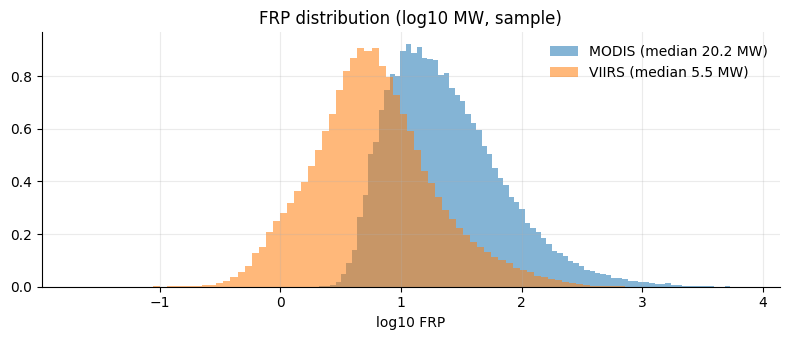

In [8]:
fig, ax = plt.subplots(figsize=(8, 3.5))
for inst in ['MODIS', 'VIIRS']:
    v = q(f"SELECT frp_mw FROM h WHERE instrument = '{inst}' AND frp_mw > 0 USING SAMPLE 400000").frp_mw
    ax.hist(np.log10(v), bins=80, alpha=.55, density=True, label=f'{inst} (median {v.median():.1f} MW)')
ax.set(title='FRP distribution (log10 MW, sample)', xlabel='log10 FRP'); ax.legend(frameon=False); plt.tight_layout(); plt.show()

**Reading.** VIIRS I4 saturates at 367 K in 8.4% of rows and MODIS T21 at about 500 K in a few hundred rows; FRP stays valid for most of them and is zero or negative in
0.06% of VIIRS rows (18 negative values, all Suomi-NPP) and 317 MODIS rows. FRP and brightness cannot be compared between sensors without caring for this clipping (block 3).
No missing FRP or brightness. Five VIIRS rows have a brightness channel equal to 0 (3 mid-infrared, 2 thermal): negligible, kept in the table, and any brightness analysis must ignore zeros.

## 1.4 Standard (SP) against near-real-time (NRT) data

Which months are NRT, how big is the difference, and is **September 2026** a real peak?

In [9]:
m = q('''SELECT strftime(burn_date, '%Y-%m') m, instrument, processing, count(*) n FROM h WHERE burn_date >= '2025-07-01' GROUP BY ALL''')
display(m.pivot_table(index='m', columns=['instrument', 'processing'], values='n', fill_value=0).astype(int))
nrt_files = q("SELECT DISTINCT source_file FROM h WHERE processing = 'NRT' ORDER BY 1").source_file.tolist()
print(len(nrt_files), 'source files hold NRT rows')

# Keep a dated copy of the NRT files: SP will replace them in about 5 months and we want to measure the revision.
stamp = dt.date.today().isoformat()
dest = DATA / 'archive_nrt' / stamp
if not dest.exists():
    for f in nrt_files:
        src = DATA / f
        if src.exists():
            (dest / Path(f).parent).mkdir(parents=True, exist_ok=True); shutil.copy2(src, dest / f)
    print('copied', len(nrt_files), 'files to', dest.relative_to(ROOT))
else:
    print('copy already exists:', dest.relative_to(ROOT))

instrument MODIS        VIIRS       
processing   NRT    SP    NRT     SP
m                                   
2025-07        0  3750      0  37098
2025-08        0  9534      0  83206
2025-09        0  7398      0  65002
2025-10        0  5852      0  60691
2025-11        0  3885      0  39184
2025-12        0  3051      0  31797
2026-01        0  4588      0  55428
2026-02        0  2648      0  33356
2026-03        0  2667      0  30461
2026-04        0  1698      0  21626
2026-05        0  1578      0  24628
2026-06        0   795      0  15764
2026-07        0  2366    801  27593
2026-08        9  2261  28079      0
2026-09     7247     0  76584      0
2026-10     1757     0  21148      0
2026-11     2688     0  16595      0

15 source files hold NRT rows
copy already exists: NASA_Data_Sources\archive_nrt\2026-11-14


In [10]:
# September 2026 against earlier years, on NOAA-20 (complete since 2018) and per region.
r = q('''SELECT year(burn_date) y, month(burn_date) mo, count(*) n FROM h
  WHERE satellite = 'NOAA-20' AND month(burn_date) IN (8, 9, 10) AND burn_date < '2026-11-01' GROUP BY ALL''').pivot(index='y', columns='mo', values='n')
r['Sep/Aug'] = (r[9] / r[8]).round(2); r['Sep/Oct'] = (r[9] / r[10]).round(2)
print('NOAA-20 rows per month and ratios:'); display(r.rename(columns={8: 'Aug', 9: 'Sep', 10: 'Oct'}))

reg = q('''SELECT country, admin1, strftime(burn_date, '%Y-%m') m, count(*) n FROM h
  WHERE instrument = 'VIIRS' AND burn_date BETWEEN '2026-08-01' AND '2026-10-31' GROUP BY ALL''').pivot_table(index=['country', 'admin1'], columns='m', values='n', fill_value=0)
reg['Sep share'] = (reg['2026-09'] / reg.sum(axis=1)).round(2)
print('Top regions in September 2026 (VIIRS, all satellites):'); display(reg.sort_values('2026-09', ascending=False).head(8))

NOAA-20 rows per month and ratios:


mo,Aug,Sep,Oct,Sep/Aug,Sep/Oct
y,,,,,
2018,50766,32695,10639,0.64,3.07
2019,38074,45074,21056,1.18,2.14
2020,110432,81287,55242,0.74,1.47
2021,49987,26081,32137,0.52,0.81
2022,40321,46976,31402,1.17,1.50
2023,31524,20704,22933,0.66,0.90
2024,32222,43700,19253,1.36,2.27
2025,28012,21294,20904,0.76,1.02
2026,9699,25334,6574,2.61,3.85


Top regions in September 2026 (VIIRS, all satellites):


m                              2026-08  2026-09  2026-10  Sep share
country   admin1                                                   
Argentina Formosa               3167.0  13806.0   2015.0       0.73
          Santiago del Estero   5112.0  12774.0   2734.0       0.62
          Corrientes            2853.0  10124.0   1368.0       0.71
          Santa Fe              1691.0   9073.0   2434.0       0.69
          Chaco                 2101.0   6682.0   2078.0       0.62
          Entre Ríos             359.0   3300.0    429.0       0.81
          Salta                 1616.0   3048.0   1076.0       0.53
          Buenos Aires          1324.0   2372.0    774.0       0.53

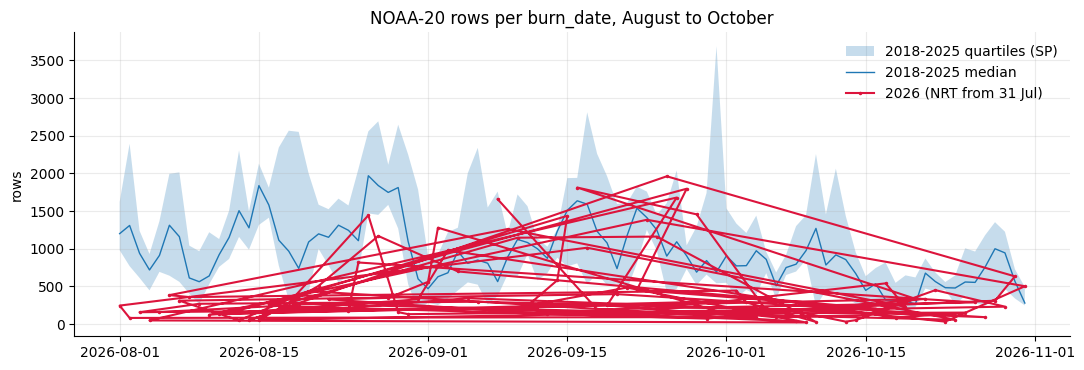

In [11]:
clim = q('''SELECT burn_date, count(*) n FROM h WHERE instrument = 'VIIRS' AND satellite = 'NOAA-20' AND burn_date BETWEEN '2018-08-01' AND '2025-10-31'
  AND month(burn_date) IN (8, 9, 10) GROUP BY 1''')
clim['doy'] = pd.to_datetime(clim.burn_date).dt.strftime('%m-%d')
band = clim.groupby('doy').n.quantile([.25, .5, .75]).unstack()
cur = q('''SELECT burn_date, count(*) n FROM h WHERE satellite = 'NOAA-20' AND burn_date BETWEEN '2026-08-01' AND '2026-10-31' GROUP BY 1''').assign(doy=lambda x: pd.to_datetime(x.burn_date).dt.strftime('%m-%d'))
x = pd.to_datetime('2026-' + band.index)
fig, ax = plt.subplots(figsize=(11, 3.8))
ax.fill_between(x, band[.25], band[.75], alpha=.25, label='2018-2025 quartiles (SP)'); ax.plot(x, band[.5], lw=1, label='2018-2025 median')
ax.plot(pd.to_datetime('2026-' + cur.doy), cur.n, color='crimson', marker='.', ms=3, label='2026 (NRT from 31 Jul)')
ax.set(title='NOAA-20 rows per burn_date, August to October', ylabel='rows'); ax.legend(frameon=False); plt.tight_layout(); plt.show()

**Reading.** On NOAA-20, September 2026 holds 2.6 times the rows of August and 3.9 times those of October: the highest ratios since 2018 (previous maxima 1.4 and 3.1).
But the peak is made of pulses of a few days (the daily plot) concentrated in the northern Argentine regions that dominate every year (Formosa, Santiago del Estero, Corrientes, Santa Fe, Chaco),
and all four satellites show it. A uniform inflation by NRT processing would not look like this. What stands out is that August and October 2026 are far below the earlier years, not that September is high:
September 2026 (25k NOAA-20 rows) is in the range of 2024 (44k) and 2025 (21k).
We conclude: **September is plausibly real, and the NRT months are not shown to be inflated**, but they stay flagged `provisional`, and the 2026 anomaly is shown with that label.
This cannot be proven without SP: the archived NRT copy lets us measure the revision when SP replaces them (between January 2027 for August and April 2027 for November).

## 1.5 MODIS collection versions

MODIS changes version in 2018 (`6.2` to `6.03`), 2023 (`6.03` to `61.03`) and September 2026 (`6.1NRT`). Do the changes show in the series?
Three checks: Terra / Aqua and Aqua / Suomi-NPP ratios by year, the share of `fire_type` 2 by year, and a direct test of the same month through the API.

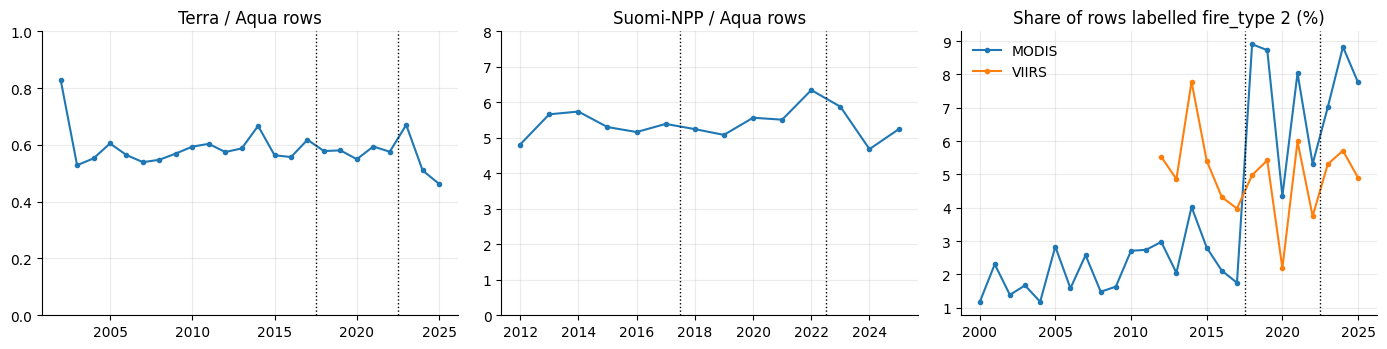

Dotted lines: MODIS version changes (6.2 -> 6.03 in 2018, 6.03 -> 61.03 in 2023).


satellite,Terra,Aqua,Suomi-NPP,Terra/Aqua,SNPP/Aqua
y,,,,,
2012,25283.0,43972.0,211541.0,0.57,4.81
2013,27115.0,46153.0,261325.0,0.59,5.66
2014,17596.0,26382.0,151424.0,0.67,5.74
2015,19701.0,34960.0,185385.0,0.56,5.30
2016,22509.0,40396.0,208550.0,0.56,5.16
2017,29167.0,47190.0,254411.0,0.62,5.39
2018,22926.0,39638.0,207916.0,0.58,5.25
2019,21314.0,36698.0,186502.0,0.58,5.08
2020,47015.0,85540.0,476064.0,0.55,5.57


In [12]:
y = q('''SELECT year(burn_date) y, satellite, count(*) n FROM h WHERE burn_date < '2026-01-01' GROUP BY ALL''').pivot(index='y', columns='satellite', values='n').fillna(0)
y['Terra/Aqua'] = y.Terra / y.Aqua.where(y.Aqua > 0)
y['SNPP/Aqua'] = y['Suomi-NPP'] / y.Aqua.where(y['Suomi-NPP'] > 0)
t2 = q('''SELECT year(burn_date) y, instrument, avg((fire_type = 2)::INT) p2 FROM h WHERE processing = 'SP' AND burn_date < '2026-01-01' GROUP BY 1, 2''').pivot(index='y', columns='instrument', values='p2')
fig, ax = plt.subplots(1, 3, figsize=(14, 3.6))
ax[0].plot(y.index, y['Terra/Aqua'], marker='.'); ax[0].set(title='Terra / Aqua rows', ylim=(0, 1))
ax[1].plot(y.index, y['SNPP/Aqua'], marker='.'); ax[1].set(title='Suomi-NPP / Aqua rows', ylim=(0, 8))
ax[2].plot(t2.index, 100 * t2.MODIS, marker='.', label='MODIS'); ax[2].plot(t2.index, 100 * t2.VIIRS, marker='.', label='VIIRS'); ax[2].set(title='Share of rows labelled fire_type 2 (%)'); ax[2].legend(frameon=False)
for a in ax:
    for yr, c in [(2017.5, 'k'), (2022.5, 'k')]: a.axvline(yr, color=c, ls=':', lw=1)
plt.tight_layout(); plt.show()
print('Dotted lines: MODIS version changes (6.2 -> 6.03 in 2018, 6.03 -> 61.03 in 2023).')
display(y.round(2).loc[2012:2025, ['Terra', 'Aqua', 'Suomi-NPP', 'Terra/Aqua', 'SNPP/Aqua']])

In [13]:
# Direct test: download one old month through the FIRMS Area API (SP) and compare it with the yearly files, row by row.
# Needs FIRMS_MAP_KEY in .env (same key as scripts/download_firms_api.sh). Files go to NASA_Data_Sources/validation/.
VAL = DATA / 'validation'; VAL.mkdir(exist_ok=True)
def fetch_month(src, start, ndays, out):
    key = None
    for line in (ROOT / '.env').read_text().splitlines():
        if line.startswith('FIRMS_MAP_KEY='): key = line.split('=', 1)[1].strip().strip('"')
    if not key: raise RuntimeError('FIRMS_MAP_KEY missing')
    d = dt.date.fromisoformat(start); end = d + dt.timedelta(days=ndays); first = True
    with open(out, 'w', encoding='utf-8') as f:
        while d < end:
            n = min(5, (end - d).days)
            txt = urllib.request.urlopen(f'https://firms.modaps.eosdis.nasa.gov/api/area/csv/{key}/{src}/-76,-56,-53,-17/{n}/{d}', timeout=300).read().decode()
            if not txt.startswith('latitude'): raise RuntimeError(f'bad response for {src} {d}')
            lines = txt.strip().split('\n'); f.write('\n'.join(lines if first else lines[1:]) + '\n'); first = False; d += dt.timedelta(days=n)

tests = [('MODIS_SP', 'MODIS', None), ('VIIRS_SNPP_SP', 'VIIRS', 'Suomi-NPP')]
res = []
for src, inst, sat_name in tests:
    f = VAL / f'{src}_2019-01.csv'
    if not f.exists():
        try: fetch_month(src, '2019-01-01', 31, f)
        except Exception as e: print('skipped', src, '-', e); continue
    a = pd.read_csv(f, dtype={'acq_time': str}); a['acq_time'] = a.acq_time.str.zfill(4)
    a['k'] = a.acq_date + '|' + a.acq_time + '|' + a.latitude.round(3).astype(str) + '|' + a.longitude.round(3).astype(str)
    cond = f"instrument = '{inst}' AND source = 'country_yearly' AND acq_date BETWEEN '2019-01-01' AND '2019-01-31' AND satellite <> 'NOAA-20'"
    t = q(f"SELECT strftime(acq_date, '%Y-%m-%d') d, acq_time, latitude, longitude, frp_mw, fire_type, version FROM h WHERE {cond}")
    t['k'] = t.d + '|' + t.acq_time + '|' + t.latitude.round(3).astype(str) + '|' + t.longitude.round(3).astype(str)
    mm = t.merge(a.drop_duplicates('k'), on='k', suffixes=('', '_api'))
    res.append(dict(product=src, yearly_rows=len(t), found_in_api=round(t.k.isin(a.k).mean(), 4), frp_equal=round(np.isclose(mm.frp_mw, mm.frp, atol=.051).mean(), 4),
                    fire_type_equal=round((mm.fire_type == mm['type']).mean(), 4), version_equal=round((mm.version.astype(str) == mm.version_api.astype(str)).mean(), 4)))
display(pd.DataFrame(res))

,product,yearly_rows,found_in_api,frp_equal,fire_type_equal,version_equal
0,MODIS_SP,2882,1.0,1.0000,1.0,1.0
1,VIIRS_SNPP_SP,6611,1.0,0.9974,1.0,1.0


**Reading.**

- Terra / Aqua stays between 0.55 and 0.67 through 2023 (no step at the 2018 version change) and **falls to 0.51 and 0.46 in 2024 and 2025**: the Terra orbit drift, not the collection.
- Suomi-NPP / Aqua is 5.1 to 5.7 in 2013-2021 with no step in 2018. After 2021 it moves between 4.7 and 6.3, in years with a 17-day Aqua outage (2022) and a 15-day Suomi-NPP outage (2022) and when the orbit drift starts,
  so that variation cannot be assigned to the collection change alone.
- **The share of `fire_type` 2 in MODIS jumps from about 2% (through 2017) to 9% (2018 and later), while VIIRS stays flat.** The newer MODIS collection labels many more rows as static sources.
  Filtering by label alone would remove 2% of MODIS rows before 2018 and 9% after: an artificial step of about 7% in the MODIS series. That is why the static-source filter in 1.6 is built from persistence in space, which has the same effect in every year.
- January 2019 fetched through the API (SP) matches the yearly files row by row: all yearly rows are found, with the same `fire_type` and version, and the same FRP within 0.05 MW (100% of MODIS rows, 99.7% of VIIRS rows; the rest are position-key ties). The version label in the yearly files is what FIRMS serves today.

## 1.6 `fire_type` and the static-source mask

`fire_type`: 0 vegetation, 1 volcano, 2 other static land source (gas flares, smelters), 3 offshore. It is empty in NRT rows.
We build a mask of **persistent cells**: 0.005 degree cells (about 500 m) with detections on many days, in many months and in many years, using VIIRS SP rows from 2012-02 to 2025-12
(VIIRS has the finest pixel). A cell that burns every month for years is not vegetation fire. The mask is checked against the labels in SP rows and then applied to every row, SP and NRT.

In [14]:
ft = q('''SELECT instrument, fire_type, count(*) n FROM h WHERE processing = 'SP' GROUP BY 1, 2''').pivot(index='fire_type', columns='instrument', values='n')
display((100 * ft / ft.sum()).round(2).rename_axis('fire_type (% of SP rows)'))
reg_t = q('''SELECT country, admin1, count(*) n, round(100 * avg((fire_type > 0)::INT), 1) pct_not_vegetation FROM h
  WHERE processing = 'SP' AND instrument = 'VIIRS' GROUP BY 1, 2 HAVING count(*) > 2000 ORDER BY 4 DESC LIMIT 8''')
print('Regions with the highest share of labelled non-vegetation rows (VIIRS SP):'); display(reg_t)

con.execute('''CREATE OR REPLACE TABLE cellstat AS SELECT CAST(floor(latitude / 0.005) AS INT) cy, CAST(floor(longitude / 0.005) AS INT) cx,
  count(*) n, count(DISTINCT burn_date) ndays, count(DISTINCT month(burn_date)) nmonths, count(DISTINCT year(burn_date)) nyears, avg((fire_type > 0)::INT) p_static
  FROM h WHERE instrument = 'VIIRS' AND processing = 'SP' AND burn_date BETWEEN '2012-02-01' AND '2025-12-31' GROUP BY 1, 2''')
tot_static = q('SELECT sum(n * p_static) s FROM cellstat').s[0]
rules = {'A: >=100 days, >=5 years': 'ndays >= 100 AND nyears >= 5',
         'B: >=60 days, >=9 months, >=5 years': 'ndays >= 60 AND nmonths >= 9 AND nyears >= 5',
         'C: >=40 days, >=8 months, >=4 years': 'ndays >= 40 AND nmonths >= 8 AND nyears >= 4',
         'D: >=30 days, >=6 months, >=4 years': 'ndays >= 30 AND nmonths >= 6 AND nyears >= 4'}
ev = []
for name, cond in rules.items():
    r = q(f'SELECT count(*) cells, sum(n) rows_, sum(n * p_static) static_rows FROM cellstat WHERE {cond}').iloc[0]
    ev.append(dict(rule=name, cells=int(r.cells), rows=int(r.rows_), precision=round(r.static_rows / r.rows_, 3), recall=round(r.static_rows / tot_static, 3)))
print('Mask rules against the SP labels (precision: share of masked rows labelled non-vegetation; recall: share of labelled rows that are masked):')
display(pd.DataFrame(ev))

instrument,MODIS,VIIRS
fire_type (% of SP rows),,
0,96.23,94.77
1,0.15,0.18
2,3.61,4.75
3,0.01,0.29


Regions with the highest share of labelled non-vegetation rows (VIIRS SP):


,country,admin1,n,pct_not_vegetation
0,Chile,Región de Antofagasta,67675,61.5
1,Chile,Región de Valparaíso,41563,51.1
2,Chile,Región de Atacama,41902,47.5
3,Chile,Región del Libertador Bernardo O'Higgins,59374,42.8
4,Argentina,Neuquén,143986,33.9
5,Argentina,Buenos Aires,243918,33.3
6,Chile,Región Metropolitana de Santiago,34616,24.2
7,Chile,Región de Los Lagos,14604,21.1


Mask rules against the SP labels (precision: share of masked rows labelled non-vegetation; recall: share of labelled rows that are masked):


,rule,cells,rows,precision,recall
0,"A: >=100 days, >=5 years",383,297790,0.878,0.895
1,"B: >=60 days, >=9 months, >=5 years",483,305530,0.869,0.909
2,"C: >=40 days, >=8 months, >=4 years",654,322553,0.842,0.930
3,"D: >=30 days, >=6 months, >=4 years",881,333448,0.818,0.934


483 persistent cells; mask saved to NASA_Data_Sources\processed\quality\static_mask_cells.parquet


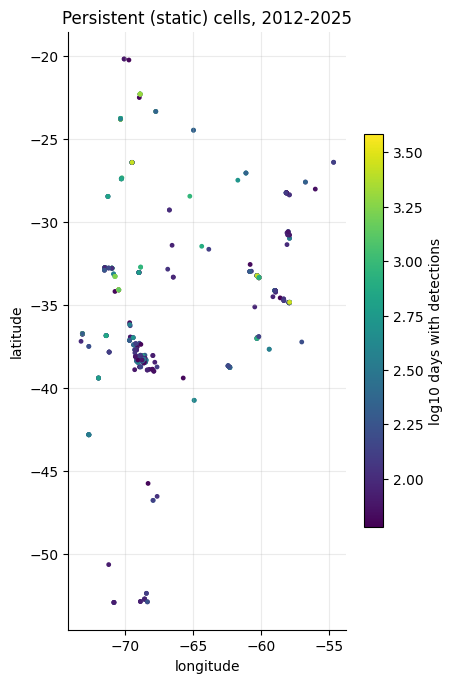

Largest persistent cells by region:


,country,admin1,rows_
0,Argentina,Buenos Aires,89668
1,Argentina,Neuquén,78186
2,Chile,Región de Antofagasta,43286
3,Chile,Región del Libertador Bernardo O'Higgins,26308
4,Chile,Región de Valparaíso,22766
5,Argentina,Santa Fe,21233


In [15]:
RULE = rules['B: >=60 days, >=9 months, >=5 years']   # chosen rule (see decisions)
con.execute(f'CREATE OR REPLACE TABLE mask AS SELECT cy, cx, n, ndays, nmonths, nyears FROM cellstat WHERE {RULE}')
# Dilate to 0.01 degree cells and their 8 neighbours, so the 1 km MODIS pixels and NRT rows match too.
con.execute('''CREATE OR REPLACE TABLE mask_c AS SELECT DISTINCT CAST(floor(cy * 0.005 / 0.01) AS INT) + dy y, CAST(floor(cx * 0.005 / 0.01) AS INT) + dx x
  FROM mask, (SELECT unnest([-1, 0, 1]) dy), (SELECT unnest([-1, 0, 1]) dx)''')
mk = q('SELECT cy * 0.005 + 0.0025 lat, cx * 0.005 + 0.0025 lon, ndays FROM mask')
mk.to_parquet(OUT / 'static_mask_cells.parquet', index=False)
print(len(mk), 'persistent cells; mask saved to', (OUT / 'static_mask_cells.parquet').relative_to(ROOT))

fig, ax = plt.subplots(figsize=(4.5, 7.5))
sc = ax.scatter(mk.lon, mk.lat, c=np.log10(mk.ndays), s=6, cmap='viridis'); plt.colorbar(sc, label='log10 days with detections', shrink=.6)
ax.set(title='Persistent (static) cells, 2012-2025', xlabel='longitude', ylabel='latitude'); ax.set_aspect(1 / np.cos(np.radians(35)))
plt.tight_layout(); plt.show()
print('Largest persistent cells by region:')
display(q('''SELECT h.country, h.admin1, count(*) rows_ FROM h JOIN mask_c m ON m.y = CAST(floor(h.latitude / 0.01) AS INT) AND m.x = CAST(floor(h.longitude / 0.01) AS INT)
  WHERE h.instrument = 'VIIRS' GROUP BY 1, 2 ORDER BY 3 DESC LIMIT 6'''))

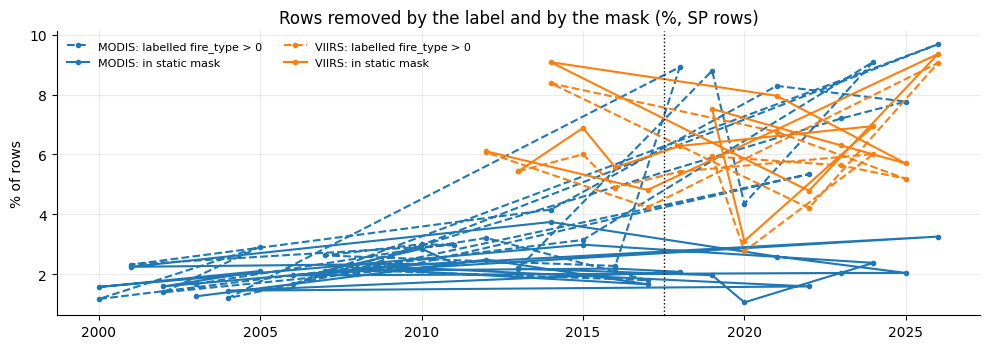

NRT rows in the mask (2026):


,instrument,processing,pct_in_mask
0,MODIS,NRT,1.78
1,MODIS,SP,3.26
2,VIIRS,NRT,5.18
3,VIIRS,SP,9.36


In [16]:
con.execute('''CREATE OR REPLACE TABLE flagged AS SELECT year(burn_date) y, instrument, processing, fire_type, (m.x IS NOT NULL) in_mask
  FROM h LEFT JOIN mask_c m ON m.y = CAST(floor(latitude / 0.01) AS INT) AND m.x = CAST(floor(longitude / 0.01) AS INT)''')
fl = q('''SELECT y, instrument, avg(in_mask::INT) p_mask, avg((fire_type > 0)::INT) p_label FROM flagged WHERE processing = 'SP' GROUP BY 1, 2''')
fig, ax = plt.subplots(figsize=(10, 3.6))
for inst, c in [('MODIS', 'tab:blue'), ('VIIRS', 'tab:orange')]:
    g = fl[fl.instrument == inst]
    ax.plot(g.y, 100 * g.p_label, color=c, ls='--', marker='.', label=f'{inst}: labelled fire_type > 0'); ax.plot(g.y, 100 * g.p_mask, color=c, marker='o', ms=3, label=f'{inst}: in static mask')
ax.axvline(2017.5, color='k', ls=':', lw=1); ax.set(title='Rows removed by the label and by the mask (%, SP rows)', ylabel='% of rows'); ax.legend(frameon=False, fontsize=8, ncol=2)
plt.tight_layout(); plt.show()
print('NRT rows in the mask (2026):'); display(q("SELECT instrument, processing, round(100 * avg(in_mask::INT), 2) pct_in_mask FROM flagged WHERE y = 2026 GROUP BY 1, 2 ORDER BY 1, 2"))

**Reading.** Rule B (at least 60 days with detections, in at least 9 calendar months and 5 different years) selects a few hundred cells,
(483 cells) and 87% of the rows inside them are labelled non-vegetation in SP, which captures 91% of all labelled rows in VIIRS. The rows inside the mask are mostly in Buenos Aires province, Neuquen
(oil and gas fields), Antofagasta, O'Higgins, Valparaiso and Santa Fe (industry, mines, flares).
**The mask removes 1 to 4% of MODIS rows in every year, with no step in 2018, while the label jumps from 2% to 9% at the collection change.** The mask is therefore applied to all rows,
and `fire_type` is used only for volcano (1) and offshore (3) rows of SP data.

## 1.7 Confidence

MODIS confidence is 0-100 (mapped to low / nominal / high with thresholds 30 and 80). VIIRS confidence is a category. The scales are not equivalent,
so each sensor is evaluated on its own.

In [17]:
cf = q('''SELECT instrument, daynight, confidence_level, count(*) n FROM h WHERE processing = 'SP' GROUP BY ALL''').pivot_table(index=['instrument', 'daynight'], columns='confidence_level', values='n', fill_value=0)
display((100 * cf.div(cf.sum(axis=1), axis=0)).round(1).rename_axis(index=['instrument', 'day/night'], columns='% of rows'))

base = "burn_date BETWEEN '2019-01-01' AND '2021-12-31' AND processing = 'SP' AND fire_type = 0"
r = q(f'''SELECT satellite, count(*) all_rows, count(*) FILTER (WHERE confidence_level <> 'low') without_low, count(*) FILTER (WHERE confidence_level = 'high') high_only
  FROM h WHERE {base} GROUP BY 1''').set_index('satellite')
ratio = pd.DataFrame({'all rows': r.loc['Suomi-NPP', 'all_rows'] / r.loc['Aqua', 'all_rows'], 'without low': r.loc['Suomi-NPP', 'without_low'] / r.loc['Aqua', 'without_low'],
                      'high only': r.loc['Suomi-NPP', 'high_only'] / r.loc['Aqua', 'high_only']}, index=['Suomi-NPP / Aqua rows, 2019-2021']).round(2)
display(ratio)
lowreg = q('''SELECT country, admin1, round(100 * avg((confidence_level = 'low')::INT), 1) pct_low_day, count(*) n FROM h
  WHERE instrument = 'VIIRS' AND daynight = 'D' AND processing = 'SP' GROUP BY 1, 2 HAVING count(*) > 20000 ORDER BY 3 DESC LIMIT 8''')
print('VIIRS daytime rows flagged low, by region (regions with more than 20,000 rows):'); display(lowreg)

% of rows             high   low  nominal
instrument day/night                     
MODIS      D          27.5   4.7     67.7
           N          48.6   7.0     44.4
VIIRS      D           9.6  12.6     77.9
           N           1.8   0.0     98.2

,all rows,without low,high only
"Suomi-NPP / Aqua rows, 2019-2021",5.42,5.18,1.3


VIIRS daytime rows flagged low, by region (regions with more than 20,000 rows):


,country,admin1,pct_low_day,n
0,Chile,Región de Atacama,49.3,24299
1,Chile,Región de Antofagasta,47.8,33569
2,Argentina,San Juan,19.4,30902
3,Argentina,Salta,17.4,218618
4,Argentina,Jujuy,16.5,30948
5,Argentina,Catamarca,16.0,22231
6,Argentina,Formosa,15.1,603425
7,Argentina,Neuquén,15.1,41044


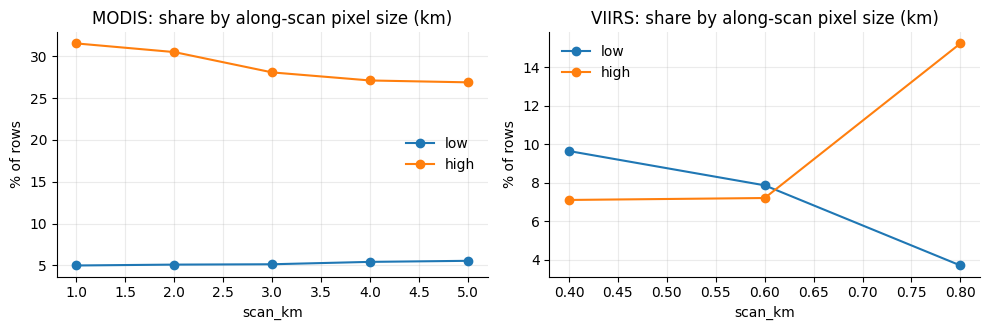

In [18]:
sc = q('''SELECT instrument, CASE WHEN instrument = 'MODIS' THEN round(scan_km) ELSE round(scan_km * 5) / 5 END sbin, count(*) n,
  100 * avg((confidence_level = 'low')::INT) p_low, 100 * avg((confidence_level = 'high')::INT) p_high FROM h WHERE processing = 'SP' GROUP BY 1, 2 ORDER BY 1, 2''')
fig, ax = plt.subplots(1, 2, figsize=(10, 3.4))
for i, inst in enumerate(['MODIS', 'VIIRS']):
    g = sc[sc.instrument == inst]; ax[i].plot(g.sbin, g.p_low, marker='o', label='low'); ax[i].plot(g.sbin, g.p_high, marker='o', label='high')
    ax[i].set(title=f'{inst}: share by along-scan pixel size (km)', xlabel='scan_km', ylabel='% of rows'); ax[i].legend(frameon=False)
plt.tight_layout(); plt.show()

**Reading.** VIIRS `low` exists only in the daytime and is **concentrated in the Atacama desert (48 to 49% of daytime rows in Antofagasta and Atacama) and the north-west** (15-19% in Salta, Jujuy, Catamarca, San Juan, La Rioja):
sun glint on bare ground, the classic false alarm. MODIS `low` is 5-7% and evenly spread. Dropping `low` removes about 9% of VIIRS and 5% of MODIS rows and moves the Suomi-NPP / Aqua ratio from 5.4 to 5.2 only.
`high only` is not usable: it keeps 30% of MODIS rows and 7% of VIIRS rows and sends the ratio to 1.3 because the scales mean different things.
Recommendation: **drop `low` in both sensors**.

## 1.8 Geography

Rows without region, the 1,205 border disagreements with FIRMS, and the areas that are not part of the analysis.

In [19]:
polys, meta = [], []
for c in ['Chile', 'Argentina']:
    gj = json.load(open(DATA / 'boundaries' / f'{c}.geojson', encoding='utf-8'))
    for f in gj['features']:
        polys.append(shape(f['geometry'])); meta.append(dict(country=c, **{k: v for k, v in f['properties'].items()}))
name_key = 'nam' if 'nam' in meta[-1] else 'shapeName'
admin_names = [m.get('nam') or m.get('shapeName') for m in meta]
tree = STRtree(polys)

no = q('SELECT satellite, acq_datetime, latitude, longitude, country_firms, country, source FROM h WHERE admin1 IS NULL')
pts = shapely.points(no.longitude.values, no.latitude.values)
idx = tree.nearest(pts)
no['dist_km'] = [polys[i].distance(p) * 111.0 for i, p in zip(idx, pts)]   # 1 degree = 111 km (upper bound east-west)
no['nearest_region_idx'] = idx
print(len(no), 'rows without region; by FIRMS country:', no.country_firms.value_counts().to_dict())
print(no.dist_km.describe(percentiles=[.5, .9, .99]).round(2).to_dict())
for t in [1, 2, 5, 10]: print(f'  within {t} km of a polygon: {(no.dist_km <= t).sum()} rows')

10476 rows without region; by FIRMS country: {'Argentina': 9736, 'Chile': 740}
{'count': 10476.0, 'mean': 0.71, 'std': 0.59, 'min': 0.0, '50%': 0.59, '90%': 1.5, '99%': 2.52, 'max': 7.33}
  within 1 km of a polygon: 7664 rows
  within 2 km of a polygon: 10085 rows
  within 5 km of a polygon: 10473 rows
  within 10 km of a polygon: 10476 rows


In [20]:
# Fix: assign the nearest region within 5 km. The other 3 rows stay without region.
TOL_KM = 5
fix = no[no.dist_km <= TOL_KM].copy()
fix['country_fixed'] = [meta[i]['country'] for i in fix.nearest_region_idx]
fix['admin1_fixed'] = [admin_names[i] for i in fix.nearest_region_idx]
print('Country assigned by nearest polygon agrees with FIRMS label in', round((fix.country_fixed == fix.country_firms).mean() * 100, 2), '% of the', len(fix), 'rows')

# Border disagreements between our label and FIRMS
dis = q('SELECT latitude, longitude, country_firms, country FROM h WHERE country_firms IS NOT NULL AND country_firms <> country')
cpoly = {c: shapely.unary_union([p for p, m in zip(polys, meta) if m['country'] == c]) for c in ['Chile', 'Argentina']}
dpts = shapely.points(dis.longitude.values, dis.latitude.values)
dis['dist_km'] = [cpoly[c].distance(p) * 111.0 for c, p in zip(dis.country_firms, dpts)]   # distance to the polygon FIRMS says
print(len(dis), 'rows where our country differs from FIRMS:', dis.groupby(['country_firms', 'country']).size().to_dict())
print('Distance to the FIRMS country polygon (km, upper bound):', dis.dist_km.describe(percentiles=[.5, .9, .99]).round(2).to_dict())

# Areas outside the analysis
out_ = q('''SELECT count(*) FILTER (WHERE longitude < -76) easter_island,
  count(*) FILTER (WHERE admin1 LIKE 'Tierra del Fuego%' AND longitude > -63.5) malvinas FROM h''')
display(out_)

Country assigned by nearest polygon agrees with FIRMS label in 99.78 % of the 10473 rows


1205 rows where our country differs from FIRMS: {('Argentina', 'Chile'): 552, ('Chile', 'Argentina'): 653}
Distance to the FIRMS country polygon (km, upper bound): {'count': 1205.0, 'mean': 0.77, 'std': 1.14, 'min': 0.0, '50%': 0.32, '90%': 2.16, '99%': 5.36, 'max': 9.16}


,easter_island,malvinas
0,467,130


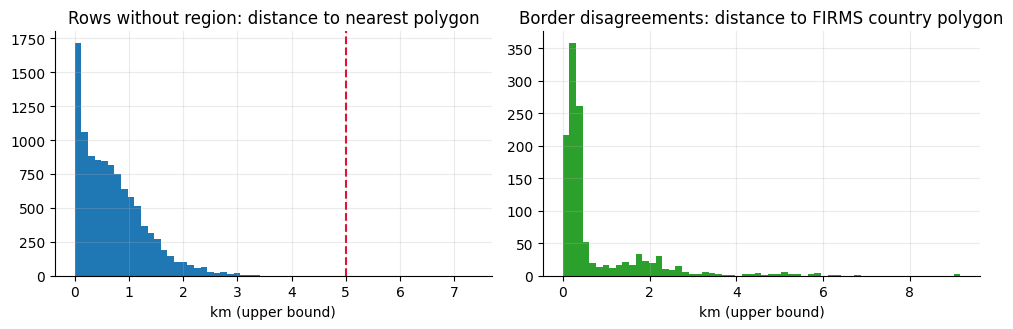

In [21]:
fig, ax = plt.subplots(1, 2, figsize=(10, 3.4))
ax[0].hist(no.dist_km, bins=60); ax[0].axvline(TOL_KM, color='crimson', ls='--'); ax[0].set(title='Rows without region: distance to nearest polygon', xlabel='km (upper bound)')
ax[1].hist(dis.dist_km, bins=60, color='tab:green'); ax[1].set(title='Border disagreements: distance to FIRMS country polygon', xlabel='km (upper bound)')
plt.tight_layout(); plt.show()

**Reading.** Every row without region is within 7.3 km of a polygon and 99.97% are within 5 km (coastal rows, because the polygons are simplified at about 100 m and the coast has rocks and islets).
They get the nearest region within a 5 km tolerance (3 rows stay without region). The 1,205 border disagreements are rows that sit within a few kilometres of the Andean border, where the two polygon sources do not share a line.
Easter Island (467 rows, longitude west of -76) and the Malvinas / Falklands (130 rows) are flagged `outside_analysis`.

## 1.9 Scan geometry

The pixel grows towards the swath edge (MODIS from 1 km to about 4.8 km along-scan, VIIRS from 0.32 to 0.80 km). Larger pixels see more area but are less sensitive.

,instrument,sbin,n,area_median_km2,frp_median,share_pct
0,MODIS,1.0,1149268,1.100,13.200000,59.5
1,MODIS,2.0,489676,2.340,26.200001,25.3
2,MODIS,3.0,182873,4.640,47.700001,9.5
3,MODIS,4.0,89046,7.020,72.900002,4.6
4,MODIS,5.0,21586,9.200,93.000000,1.1
5,VIIRS,0.4,4214327,0.179,4.800000,69.0
6,VIIRS,0.6,1720649,0.291,7.000000,28.2
7,VIIRS,0.8,174955,0.562,10.100000,2.9


instrument,MODIS,VIIRS
scan_km bin,,
0.4,NaN,2.16
0.6,NaN,4.68
0.8,NaN,12.51
1.0,0.00,NaN
2.0,0.01,NaN
3.0,0.18,NaN
4.0,1.50,NaN
5.0,2.12,NaN


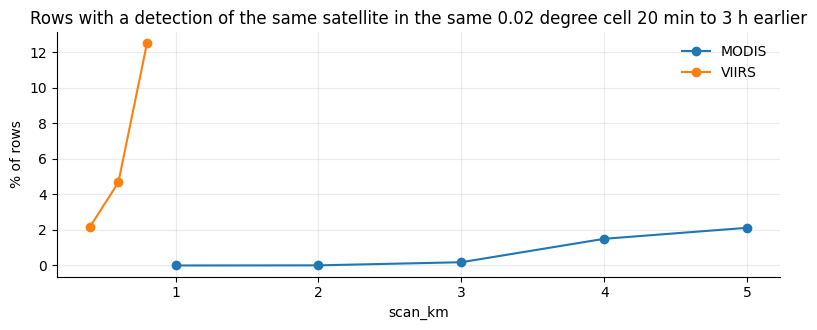

In [22]:
geo = q('''SELECT instrument, CASE WHEN instrument = 'MODIS' THEN round(scan_km) ELSE round(scan_km * 5) / 5 END sbin, count(*) n,
  round(median(pixel_area_km2), 3) area_median_km2, round(median(frp_mw), 1) frp_median FROM h GROUP BY 1, 2 ORDER BY 1, 2''')
geo['share_pct'] = (100 * geo.n / geo.groupby('instrument').n.transform('sum')).round(1)
display(geo)

re = q('''WITH t AS (SELECT instrument, scan_km, ts, lag(ts) OVER (PARTITION BY satellite, CAST(floor(latitude / 0.02) AS INT), CAST(floor(longitude / 0.02) AS INT) ORDER BY ts) prev FROM h)
SELECT instrument, CASE WHEN instrument = 'MODIS' THEN round(scan_km) ELSE round(scan_km * 5) / 5 END sbin, count(*) n,
  100 * avg((ts > prev AND ts - prev <= INTERVAL 3 HOUR AND ts - prev >= INTERVAL 20 MINUTE)::INT) pct_seen_before_within_3h FROM t GROUP BY 1, 2 ORDER BY 1, 2''')
display(re.pivot(index='sbin', columns='instrument', values='pct_seen_before_within_3h').round(2).rename_axis('scan_km bin'))
fig, ax = plt.subplots(figsize=(8, 3.4))
for inst, g in re.groupby('instrument'): ax.plot(g.sbin, g.pct_seen_before_within_3h, marker='o', label=inst)
ax.set(title='Rows with a detection of the same satellite in the same 0.02 degree cell 20 min to 3 h earlier', xlabel='scan_km', ylabel='% of rows'); ax.legend(frameon=False)
plt.tight_layout(); plt.show()

**Reading.** 60% of MODIS rows come from pixels near nadir (bin 1, median area 1.1 km2) and 5.7% from the two outer bins (median 7 to 9 km2); the FRP median grows from 13 MW at nadir to 93 MW at the edge:
only bigger fires are detected in the large edge pixels. VIIRS pixels grow from 0.18 to 0.56 km2 and 3% of rows are in the outer bin. The table and the plot above give the share of rows that repeat a detection of the same satellite
in the same 0.02 degree cell 20 minutes to 3 hours earlier, per scan bin: VIIRS goes from 2.2% at nadir to 12.5% in the outer bin, MODIS from 0% to about 2%. We do not drop edge pixels: block 3 tests the scan angle as a covariate of the MODIS / VIIRS ratio.

## Decisions: the recommended filter and its effect

Filter `keep` (applied to SP and NRT rows):

1. Drop `confidence_level = 'low'`.
2. Drop rows inside the static-source mask (rule B), all years, both sensors.
3. Drop `fire_type` 1 (volcano) and 3 (offshore) in SP rows.
4. Drop rows `outside_analysis` (Easter Island, Malvinas / Falklands).
5. Rows without region take the nearest region within 5 km (`admin1_fixed`).

Rows are kept in the table and **flagged**, not deleted: the file `quality_flags.parquet` joins to the hotspot table by (`satellite`, `acq_datetime`, `latitude`, `longitude`).
`provisional` is true for NRT rows. The days of a likely outage are listed in `outage_days.csv`.

In [23]:
con.execute('''CREATE OR REPLACE TABLE flags AS
SELECT h.satellite, h.acq_datetime, h.latitude, h.longitude, h.instrument, h.processing,
  (m.x IS NOT NULL) in_static_mask,
  coalesce(h.longitude < -76 OR (h.admin1 LIKE 'Tierra del Fuego%' AND h.longitude > -63.5), false) outside_analysis,
  coalesce(h.confidence_level = 'low', false) is_low, coalesce(h.processing = 'SP' AND h.fire_type IN (1, 3), false) is_volcano_offshore,
  (h.processing = 'NRT') provisional, h.burn_date
FROM h LEFT JOIN mask_c m ON m.y = CAST(floor(h.latitude / 0.01) AS INT) AND m.x = CAST(floor(h.longitude / 0.01) AS INT)''')
con.execute('''ALTER TABLE flags ADD COLUMN keep BOOLEAN''')
con.execute('''UPDATE flags SET keep = NOT (in_static_mask OR outside_analysis OR is_low OR is_volcano_offshore)''')

fx = fix[['satellite', 'acq_datetime', 'latitude', 'longitude', 'country_fixed', 'admin1_fixed']]
con.register('fixdf', fx)
con.execute('''CREATE OR REPLACE TABLE flags2 AS SELECT f.*, x.admin1_fixed FROM flags f LEFT JOIN fixdf x
  ON x.satellite = f.satellite AND x.acq_datetime = f.acq_datetime AND x.latitude = f.latitude AND x.longitude = f.longitude''')
con.execute(f"COPY (SELECT satellite, acq_datetime, latitude, longitude, in_static_mask, outside_analysis, is_low, is_volcano_offshore, provisional, keep, admin1_fixed FROM flags2) TO '{(OUT / 'quality_flags.parquet').as_posix()}' (FORMAT PARQUET, COMPRESSION ZSTD)")
gaps[gaps.likely_outage][['satellite', 'start', 'end', 'days']].to_csv(OUT / 'outage_days.csv', index=False)
print('saved quality_flags.parquet and outage_days.csv in', OUT.relative_to(ROOT))
n_rows = q('SELECT count(*) n FROM flags2').n[0]; n_flags = q('SELECT count(*) n FROM read_parquet(\'' + (OUT / 'quality_flags.parquet').as_posix() + '\')').n[0]
print('rows with keep = NULL (must be 0):', q('SELECT count(*) n FROM flags2 WHERE keep IS NULL').n[0])
print('rows in table:', n_rows, '| rows in flags file:', n_flags, '| keys unique:', q("SELECT count(*) - count(DISTINCT (satellite, acq_datetime, latitude, longitude)) d FROM flags2").d[0] == 0)

saved quality_flags.parquet and outage_days.csv in NASA_Data_Sources\processed\quality
rows with keep = NULL (must be 0): 0


rows in table: 8042380 | rows in flags file: 8042380 | keys unique: True


In [24]:
eff = q('''SELECT instrument, count(*) rows_, sum((NOT keep)::INT) removed, sum(is_low::INT) low, sum(in_static_mask::INT) static_mask, sum(is_volcano_offshore::INT) volcano_offshore, sum(outside_analysis::INT) outside
  FROM flags2 GROUP BY 1 ORDER BY 1''')
eff['removed_pct'] = (100 * eff.removed / eff.rows_).round(2)
print('Effect of the filter (rows can match several rules):'); display(eff)

yr = q('''SELECT year(burn_date) y, satellite, count(*) n, sum(keep::INT) kept FROM flags2 WHERE burn_date < '2026-01-01' GROUP BY 1, 2''')
a = yr.pivot(index='y', columns='satellite', values=['n', 'kept']).fillna(0)
tab = pd.DataFrame({'SNPP/Aqua before': a[('n', 'Suomi-NPP')] / a[('n', 'Aqua')].where(a[('n', 'Suomi-NPP')] > 0),
                    'SNPP/Aqua after': a[('kept', 'Suomi-NPP')] / a[('kept', 'Aqua')].where(a[('kept', 'Suomi-NPP')] > 0)}).dropna().round(2)
print('Suomi-NPP / Aqua rows per year, before and after the filter:'); display(tab.T)

Effect of the filter (rows can match several rules):


,instrument,rows_,removed,low,static_mask,volcano_offshore,outside,removed_pct
0,MODIS,1932449,134206.0,97815.0,39398.0,3048.0,72.0,6.94
1,VIIRS,6109931,907654.0,548201.0,358686.0,28117.0,525.0,14.86


Suomi-NPP / Aqua rows per year, before and after the filter:


y,2012,2013,2014,2015,2016,2017,2018,2019,2020,2021,2022,2023,2024,2025
SNPP/Aqua before,4.81,5.66,5.74,5.30,5.16,5.39,5.25,5.08,5.57,5.51,6.34,5.88,4.68,5.24
SNPP/Aqua after,4.41,5.17,5.07,4.92,4.72,4.95,4.80,4.53,5.22,4.88,5.74,5.25,4.17,4.71


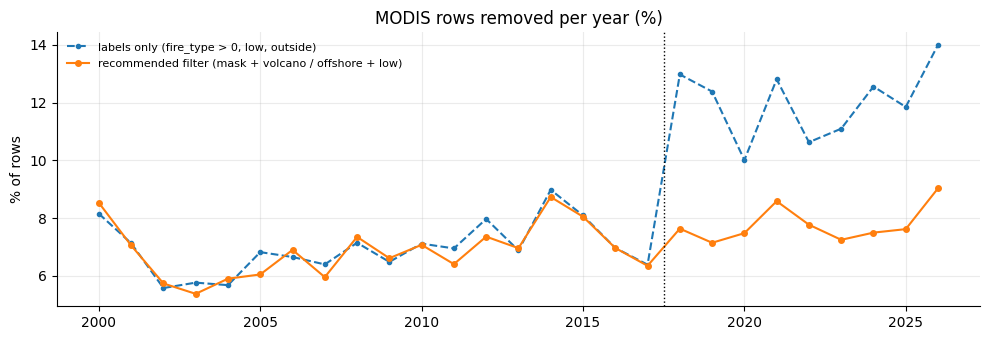

Mean % of MODIS SP rows removed, 2000-2017 / 2018-2025: recommended filter 6.9 / 7.6; labels only 7.0 / 11.8


In [25]:
fm = q('''SELECT year(burn_date) y, 100 * avg((NOT keep)::INT) removed_ours, 100 * avg((fire_type > 0 OR is_low OR outside_analysis)::INT) removed_labels
  FROM flags2 JOIN (SELECT satellite, acq_datetime, latitude, longitude, fire_type FROM h) USING (satellite, acq_datetime, latitude, longitude)
  WHERE instrument = 'MODIS' AND processing = 'SP' GROUP BY 1 ORDER BY 1''')
fig, ax = plt.subplots(figsize=(10, 3.5))
ax.plot(fm.y, fm.removed_labels, marker='.', ls='--', label='labels only (fire_type > 0, low, outside)'); ax.plot(fm.y, fm.removed_ours, marker='o', ms=4, label='recommended filter (mask + volcano / offshore + low)')
ax.axvline(2017.5, color='k', ls=':', lw=1); ax.set(title='MODIS rows removed per year (%)', ylabel='% of rows'); ax.legend(frameon=False, fontsize=8)
plt.tight_layout(); plt.show()
pre, post = fm[fm.y <= 2017], fm[(fm.y >= 2018) & (fm.y <= 2025)]
print(f'Mean % of MODIS SP rows removed, 2000-2017 / 2018-2025: recommended filter {pre.removed_ours.mean():.1f} / {post.removed_ours.mean():.1f}; labels only {pre.removed_labels.mean():.1f} / {post.removed_labels.mean():.1f}')

**Result.** The recommended filter removes 14.9% of VIIRS rows (9.0% low confidence, 5.9% static mask) and 6.9% of MODIS rows. The number printed above compares the removed share of MODIS before and after the 2018 collection change
for the recommended filter (6.9% before, 7.6% after) and for a filter by labels (7.0% before, 11.8% after): the label filter takes a much larger share after 2018, which would create a fake decline of about 5 points in MODIS counts at the collection change.
The filter lowers the Suomi-NPP / Aqua ratio by about 8% in every year (5.4 to 4.9 on average) and keeps its shape; it removes more VIIRS than MODIS rows, so it does matter for the harmonization factor: block 3 must calibrate on filtered rows.
Next: `04_calendar.ipynb` uses `quality_flags.parquet` for the calendar statistics.